In [19]:
import pandas as pd
import json
import scipy
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf

import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import numpy as np


In [20]:
df = pd.read_csv('cgmacros_final.csv')
df['Libre_trace'] = df['Libre_trace'].apply(json.loads) 

In [21]:
print(df.columns)

Index(['subject', 'Meal_Type', 'Timestamp', 'Libre_trace', 'Baseline_Libre',
       'iAUC_libre', 'AUC_libre', 'Calories', 'Carbs_g', 'Protein_g', 'Fat_g',
       'Fiber_g', 'Activity_pre_sum', 'Activity_post_sum', 'Health_group',
       'Age', 'Gender', 'BMI', 'A1c', 'Fasting_glucose', 'Insulin', 'HOMA_IR',
       'Triglycerides', 'Cholesterol', 'HDL', 'Non_HDL', 'LDL', 'VLDL',
       'Cho_HDL_ratio'],
      dtype='str')


In [22]:
# Encode gender the same way as the paper: M=1, F=-1
df['Gender_encoded'] = df['Gender'].apply(
    lambda x: 1 if str(x).strip().upper() in ['M', 'MALE'] else -1
)

# Encode the meal type once on the full dataframe
df['Meal_Type_encoded'] = df['Meal_Type'].map(
    {'Breakfast': 0, 'Lunch': 1, 'Dinner': 2}
)


# Convert macros grams → kcal (match paper exactly)
df['Carbs_kcal']   = df['Carbs_g']   * 4
df['Protein_kcal'] = df['Protein_g'] * 4
df['Fat_kcal']     = df['Fat_g']      * 9
df['Fiber_kcal']   = df['Fiber_g']    * 2
df['Net_Carb']     = df['Carbs_g']    - df['Fiber_g']

In [24]:
model_df = df[[
    'subject', 'iAUC_libre', 'AUC_libre', 'Meal_Type', 'Health_group',
    'Carbs_kcal', 'Protein_kcal', 'Fat_kcal', 'Fiber_kcal','Net_Carb',
    'Baseline_Libre', 'A1c', 'BMI', 'Age', 'Gender_encoded',
    'HOMA_IR', 'Fasting_glucose', 'Insulin', 'Triglycerides',
    'Cholesterol', 'HDL', 'Non_HDL', 'LDL', 'VLDL', 'Cho_HDL_ratio',
    'Calories', 'Activity_pre_sum', 'Activity_post_sum'
]].copy().dropna()

# Encode categoricals as proper category dtype
model_df['Meal_Type'] = pd.Categorical(model_df['Meal_Type'],categories=['Breakfast', 'Lunch','Dinner'])
model_df['Health_group']  = pd.Categorical(model_df['Health_group'],categories=['Healthy', 'PreD', 'T2D'])

print(f"Model dataset: {len(model_df)} meals, {model_df['subject'].nunique()} subjects")

Model dataset: 1170 meals, 44 subjects


In [25]:
FIXED_iAUC = (
    "iAUC_libre ~ Carbs_kcal + Protein_kcal + Fat_kcal + Fiber_kcal + Net_Carb "
    "+ Baseline_Libre + A1c + BMI + Age + Gender_encoded "
    "+ HOMA_IR + Fasting_glucose + Insulin + Triglycerides "
    "+ Cholesterol + HDL + Non_HDL + LDL + VLDL + Cho_HDL_ratio "
    "+ Calories + Activity_pre_sum + Activity_post_sum"
)

FIXED_AUC = (
    "AUC_libre ~ Carbs_kcal + Protein_kcal + Fat_kcal + Fiber_kcal + Net_Carb "
    "+ Baseline_Libre + A1c + BMI + Age + Gender_encoded "
    "+ HOMA_IR + Fasting_glucose + Insulin + Triglycerides "
    "+ Cholesterol + HDL + Non_HDL + LDL + VLDL + Cho_HDL_ratio "
    "+ Calories + Activity_pre_sum + Activity_post_sum"
)



In [28]:
def loso_evaluate(df, fit_fn, label='Model', target='iAUC_libre'):
    """
    LOSO cross-validation wrapper for any model.
    
    In each fold, one subject is held out for testing and the model is trained
    on the remaining 43 subjects. Predictions from all folds are concatenated
    into a single vector and metrics are computed globally.

    Args:
        df:      the full meal-level dataframe (1170 rows)
        fit_fn:  a function that takes a training dataframe and returns a
                 fitted model with a .predict(test_df) method
        label:   name of the model, used for printing results
        target:  name of the target column ('iAUC_libre' or 'AUC_libre')

    Returns:
        results_df: dataframe with per-meal subject, health group, true and
                    predicted values across all folds
        metrics:    dictionary with r, RMSE, MAE, R2 for the full run
    """
    subjects = df['subject'].unique()  # array of 44 subject IDs

    # accumulators - one entry per meal, appended fold by fold
    pred_list, true_list, subj_list, hgroup_list = [], [], [], []

    for sub in subjects:
        # split: everyone except sub for training, sub alone for testing
        train_df = df[df['subject'] != sub].copy()  # ~1144 meals
        test_df  = df[df['subject'] == sub].copy()  # ~26 meals

        try:
            fitted = fit_fn(train_df) # train model on 43 subjects
            preds  = fitted.predict(test_df) # predict held-out subject's meals

            pred_list.extend(preds)  # append ~26 predictions
            true_list.extend(test_df[target].values) # append ~26 true values
            subj_list.extend([sub] * len(test_df)) # track which subject
            hgroup_list.extend(test_df['Health_group'].values) # track health group
        except Exception as e:
            # if a fold fails (e.g. singular matrix), skip and report
            print(f"  Subject {sub} failed: {e}")
            continue

    # after all 44 folds: pred_list and true_list each have 1170 entries
    pred_array = np.clip(np.array(pred_list), 0, None)  # clip negatives to 0
    true_array = np.array(true_list)

    # compute metrics once on the full 1170-element vector
    r, p  = scipy.stats.pearsonr(pred_array, true_array)
    rmse  = np.sqrt(mean_squared_error(true_array, pred_array))
    mae   = mean_absolute_error(true_array, pred_array)
    r2    = r2_score(true_array, pred_array)

    print(f"\n  {label} [{target}] (LOSO, n={len(pred_list)} meals)")
    print(f"{'='*55}")
    print(f"  Pearson r : {r:.4f}  (p={p:.2e})")
    print(f"  RMSE      : {rmse:.1f}")
    print(f"  MAE       : {mae:.1f}")
    print(f"  R²        : {r2:.3f}")

    # per-meal results dataframe - useful for downstream analysis and plots
    results_df = pd.DataFrame({
        'subject':      subj_list,
        'Health_group': hgroup_list,
        'y_true':       true_array,
        'y_pred':       pred_array
    })
    return results_df, {'label': label, 'target': target,
                        'r': r, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

### 1.0. BASELINE - Ordinary Least Squares (no random effect included)

In [29]:
# C() wrapper tells statsmodels to treat those columns as categorical variables - it automatically creates dummy variables internally

def fit_ols_iauc(train_df):
    return smf.ols(FIXED_iAUC + " + C(Meal_Type) + C(Health_group)", data=train_df).fit()

def fit_ols_auc(train_df):
    return smf.ols(FIXED_AUC + " + C(Meal_Type) + C(Health_group)", data=train_df).fit()

res_ols_iauc, met_ols_iauc = loso_evaluate(model_df, fit_ols_iauc, label='OLS', target='iAUC_libre')
res_ols_auc,  met_ols_auc  = loso_evaluate(model_df, fit_ols_auc, label='OLS', target='AUC_libre')


  OLS [iAUC_libre] (LOSO, n=1170 meals)
  Pearson r : 0.3354  (p=3.81e-32)
  RMSE      : 2859.4
  MAE       : 2054.9
  R²        : 0.016

  OLS [AUC_libre] (LOSO, n=1170 meals)
  Pearson r : 0.5856  (p=1.17e-108)
  RMSE      : 4500.3
  MAE       : 2576.5
  R²        : 0.192


**iAUC results (r=0.34, R²=0.016)**

The model barely predicts iAUC. R²=0.016 means it explains only **1.6% of the variance** — essentially no better than predicting the mean for every meal. The Pearson r=0.34 shows there's *some* linear correlation, but it's weak. The RMSE of 2859 is almost as large as the standard deviation of iAUC itself (2884 from your EDA), which confirms the model adds almost no predictive value.

**AUC results (r=0.59, R²=0.19)**

Noticeably better — explains **19% of variance**, r=0.59 is a moderate correlation. This makes intuitive sense: AUC includes the baseline glucose level, which is relatively stable per subject and strongly determined by clinical features like HbA1c and fasting glucose that are in the model. So the clinical features are good at capturing **who has high baseline glucose**, but poor at capturing **how much their glucose spikes after a meal**.

### 1.1. LMM-base: random intercept per subject

In [30]:
def fit_lmm_base_iauc(train_df):
    formula = FIXED_iAUC + " + C(Meal_Type) + C(Health_group)"
    return smf.mixedlm(formula, data=train_df, groups=train_df['subject']).fit(reml=False)

def fit_lmm_base_auc(train_df):
    formula = FIXED_AUC + " + C(Meal_Type) + C(Health_group)"
    return smf.mixedlm(formula, data=train_df, groups=train_df['subject']).fit(reml=False)

res_lmm_base_iauc, met_lmm_base_iauc = loso_evaluate(model_df, fit_lmm_base_iauc, label='LMM-base', target='iAUC_libre')
res_lmm_base_auc,  met_lmm_base_auc  = loso_evaluate(model_df, fit_lmm_base_auc,label='LMM-base', target='AUC_libre')


  LMM-base [iAUC_libre] (LOSO, n=1170 meals)
  Pearson r : 0.3270  (p=1.47e-30)
  RMSE      : 2914.7
  MAE       : 2090.6
  R²        : -0.023

  LMM-base [AUC_libre] (LOSO, n=1170 meals)
  Pearson r : 0.5656  (p=7.07e-100)
  RMSE      : 4564.8
  MAE       : 2655.0
  R²        : 0.169


**Why LMM underperforms OLS here**

The random intercept is fitted on the training subjects and then has to **generalise to a completely new subject** in the test fold. Under LOSO, the held-out subject's random intercept is unknown — statsmodels predicts using only the fixed effects for new subjects, but the model was optimised assuming random effects exist. This can actually hurt generalisation compared to OLS which never tried to model subject-level structure in the first place.

This is a known issue with mixed-effects models under LOSO — the random intercepts are useful for **inference within the training set** but don't transfer to unseen subjects.

**Numbers:**
- iAUC: R² dropped from 0.016 → -0.023 (negative R² means worse than predicting the mean)
- AUC: R² dropped from 0.192 → 0.169

In [ ]:
# LMM-base: full dataset inference (no LOSO) 
formula = FIXED_iAUC + " + C(Meal_Type) + C(Health_group)"
lmm_full = smf.mixedlm(formula, data=model_df, groups=model_df['subject']).fit(reml=False)
print(lmm_full.summary())

                    Mixed Linear Model Regression Results
Model:                   MixedLM       Dependent Variable:       iAUC_libre  
No. Observations:        1170          Method:                   ML          
No. Groups:              44            Scale:                    4371734.0735
Min. group size:         14            Log-Likelihood:           -10647.4017 
Max. group size:         51            Converged:                Yes         
Mean group size:         26.6                                                
-----------------------------------------------------------------------------
                          Coef.    Std.Err.   z    P>|z|   [0.025     0.975] 
-----------------------------------------------------------------------------
Intercept                -4256.665 3368.902 -1.264 0.206 -10859.590  2346.261
C(Meal_Type)[T.Lunch]    -1082.979  188.590 -5.742 0.000  -1452.609  -713.349
C(Meal_Type)[T.Dinner]   -1357.217  172.996 -7.845 0.000  -1696.284 -1018.151
C(Heal

c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2704: RuntimeWarning: invalid value encountered in sqrt
  sdf[0:self.k_fe, 1] = np.sqrt(np.diag(self.cov_params()[0:self.k_fe]))


### 1.2. LMM-interaction: random intercept + Meal_Type × Health_group

In [31]:
def fit_lmm_interaction_iauc(train_df):
    formula = FIXED_iAUC + " + C(Meal_Type) * C(Health_group)"
    return smf.mixedlm(formula, data=train_df, groups=train_df['subject']).fit(reml=False)

def fit_lmm_interaction_auc(train_df):
    formula = FIXED_AUC + " + C(Meal_Type) * C(Health_group)"
    return smf.mixedlm(formula, data=train_df, groups=train_df['subject']).fit(reml=False)

res_lmm_interaction_iauc, met_lmm_interaction_iauc = loso_evaluate(model_df, fit_lmm_interaction_iauc,label='LMM-interaction', target='iAUC_libre')
res_lmm_interaction_auc,  met_lmm_interaction_auc  = loso_evaluate(model_df, fit_lmm_interaction_auc,label='LMM-interaction', target='AUC_libre')


  LMM-interaction [iAUC_libre] (LOSO, n=1170 meals)
  Pearson r : 0.3651  (p=3.38e-38)
  RMSE      : 2884.3
  MAE       : 2056.0
  R²        : -0.001

  LMM-interaction [AUC_libre] (LOSO, n=1170 meals)
  Pearson r : 0.5684  (p=4.31e-101)
  RMSE      : 4561.3
  MAE       : 2638.3
  R²        : 0.170


**Compared to LMM-base:**

- iAUC: r improved slightly (0.327→0.365), R² recovered from -0.023→-0.001 — essentially back to zero
- AUC: virtually identical (R² 0.169→0.170, negligible difference)

**What the interaction term adds**

The `Meal_Type × Health_group` interaction tests whether the effect of meal type on glucose response **differs across metabolic groups** — for example, whether T2D patients respond differently to breakfast vs dinner compared to healthy subjects. The slight improvement in iAUC r suggests there is *some* signal in this interaction, but it's not enough to meaningfully improve generalisation.

### 1.3. LMM-stratified: separate LMM per meal type

In [35]:
def fit_lmm_stratified_iauc(train_df):
    formula = FIXED_iAUC + " + C(Health_group)"
    return smf.mixedlm(formula, data=train_df, groups=train_df['subject']).fit(reml=False)

def fit_lmm_stratified_auc(train_df):
    formula = FIXED_AUC + " + C(Health_group)"
    return smf.mixedlm(formula, data=train_df, groups=train_df['subject']).fit(reml=False)

lmm_strat_results = {}

for meal_type in ['Breakfast', 'Lunch', 'Dinner']:
    meal_df = model_df[model_df['Meal_Type'] == meal_type].copy()
    res_iauc, met_iauc = loso_evaluate(meal_df, fit_lmm_stratified_iauc,
                                        label=f'LMM-stratified {meal_type}',
                                        target='iAUC_libre')
    res_auc,  met_auc  = loso_evaluate(meal_df, fit_lmm_stratified_auc,
                                        label=f'LMM-stratified {meal_type}',
                                        target='AUC_libre')
    lmm_strat_results[meal_type] = {
        'iAUC': (res_iauc, met_iauc),
        'AUC':  (res_auc,  met_auc)
    }


  LMM-stratified Breakfast [iAUC_libre] (LOSO, n=405 meals)
  Pearson r : 0.4965  (p=1.36e-26)
  RMSE      : 3180.5
  MAE       : 2214.7
  R²        : 0.143

  LMM-stratified Breakfast [AUC_libre] (LOSO, n=405 meals)
  Pearson r : 0.6008  (p=4.26e-41)
  RMSE      : 5328.1
  MAE       : 2830.3
  R²        : 0.223


c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed t


  LMM-stratified Lunch [iAUC_libre] (LOSO, n=369 meals)
  Pearson r : 0.4220  (p=2.29e-17)
  RMSE      : 2547.7
  MAE       : 1883.6
  R²        : 0.088


c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(



  LMM-stratified Lunch [AUC_libre] (LOSO, n=369 meals)
  Pearson r : 0.5691  (p=4.68e-33)
  RMSE      : 3924.0
  MAE       : 2406.7
  R²        : 0.126

  LMM-stratified Dinner [iAUC_libre] (LOSO, n=396 meals)
  Pearson r : 0.1347  (p=7.25e-03)
  RMSE      : 2517.7
  MAE       : 1782.0
  R²        : -0.321


c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\Laura\anaconda3\envs\biomedenv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  wa

  Subject 36 failed: Singular matrix

  LMM-stratified Dinner [AUC_libre] (LOSO, n=388 meals)
  Pearson r : 0.4253  (p=1.77e-18)
  RMSE      : 3961.8
  MAE       : 2327.8
  R²        : -0.127


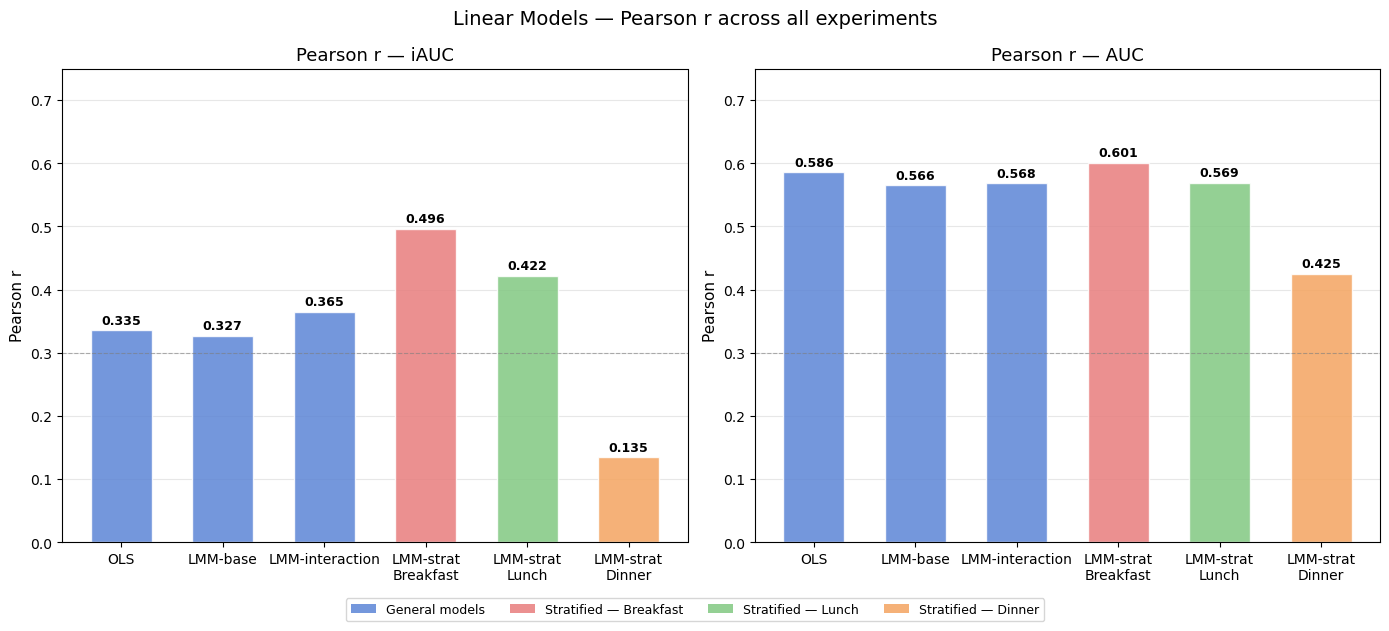

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Data
models_iauc = [
    ('OLS',                    met_ols_iauc['r']),
    ('LMM-base',               met_lmm_base_iauc['r']),
    ('LMM-interaction',        met_lmm_interaction_iauc['r']),
    ('LMM-strat\nBreakfast',   lmm_strat_results['Breakfast']['iAUC'][1]['r']),
    ('LMM-strat\nLunch',       lmm_strat_results['Lunch']['iAUC'][1]['r']),
    ('LMM-strat\nDinner',      lmm_strat_results['Dinner']['iAUC'][1]['r']),
]

models_auc = [
    ('OLS',                    met_ols_auc['r']),
    ('LMM-base',               met_lmm_base_auc['r']),
    ('LMM-interaction',        met_lmm_interaction_auc['r']),
    ('LMM-strat\nBreakfast',   lmm_strat_results['Breakfast']['AUC'][1]['r']),
    ('LMM-strat\nLunch',       lmm_strat_results['Lunch']['AUC'][1]['r']),
    ('LMM-strat\nDinner',      lmm_strat_results['Dinner']['AUC'][1]['r']),
]

# Colors: general models vs stratified 
colors = ['#5C85D6', '#5C85D6', '#5C85D6',   # general models — blue
          '#E87D7D', '#82C882', '#F4A460']     # stratified — per meal type

for ax, data, title in zip(axes,
                            [models_iauc, models_auc],
                            ['Pearson r — iAUC', 'Pearson r — AUC']):
    labels = [m[0] for m in data]
    values = [m[1] for m in data]

    bars = ax.bar(labels, values, color=colors, alpha=0.85, edgecolor='white', width=0.6)

    # value labels on top of each bar
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f'{val:.3f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

    ax.set_title(title, fontsize=13)
    ax.set_ylabel('Pearson r', fontsize=11)
    ax.set_ylim(0, 0.75)
    ax.axhline(0.3, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
    ax.yaxis.grid(True, alpha=0.3)
    ax.set_axisbelow(True)

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#5C85D6', alpha=0.85, label='General models'),
    Patch(facecolor='#E87D7D', alpha=0.85, label='Stratified — Breakfast'),
    Patch(facecolor='#82C882', alpha=0.85, label='Stratified — Lunch'),
    Patch(facecolor='#F4A460', alpha=0.85, label='Stratified — Dinner'),
]
fig.legend(handles=legend_elements, loc='lower center',
           ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.05))

plt.suptitle('Linear Models — Pearson r across all experiments', fontsize=14)
plt.tight_layout()
plt.savefig('linear_models_pearson_r.png', dpi=150, bbox_inches='tight')
plt.show()

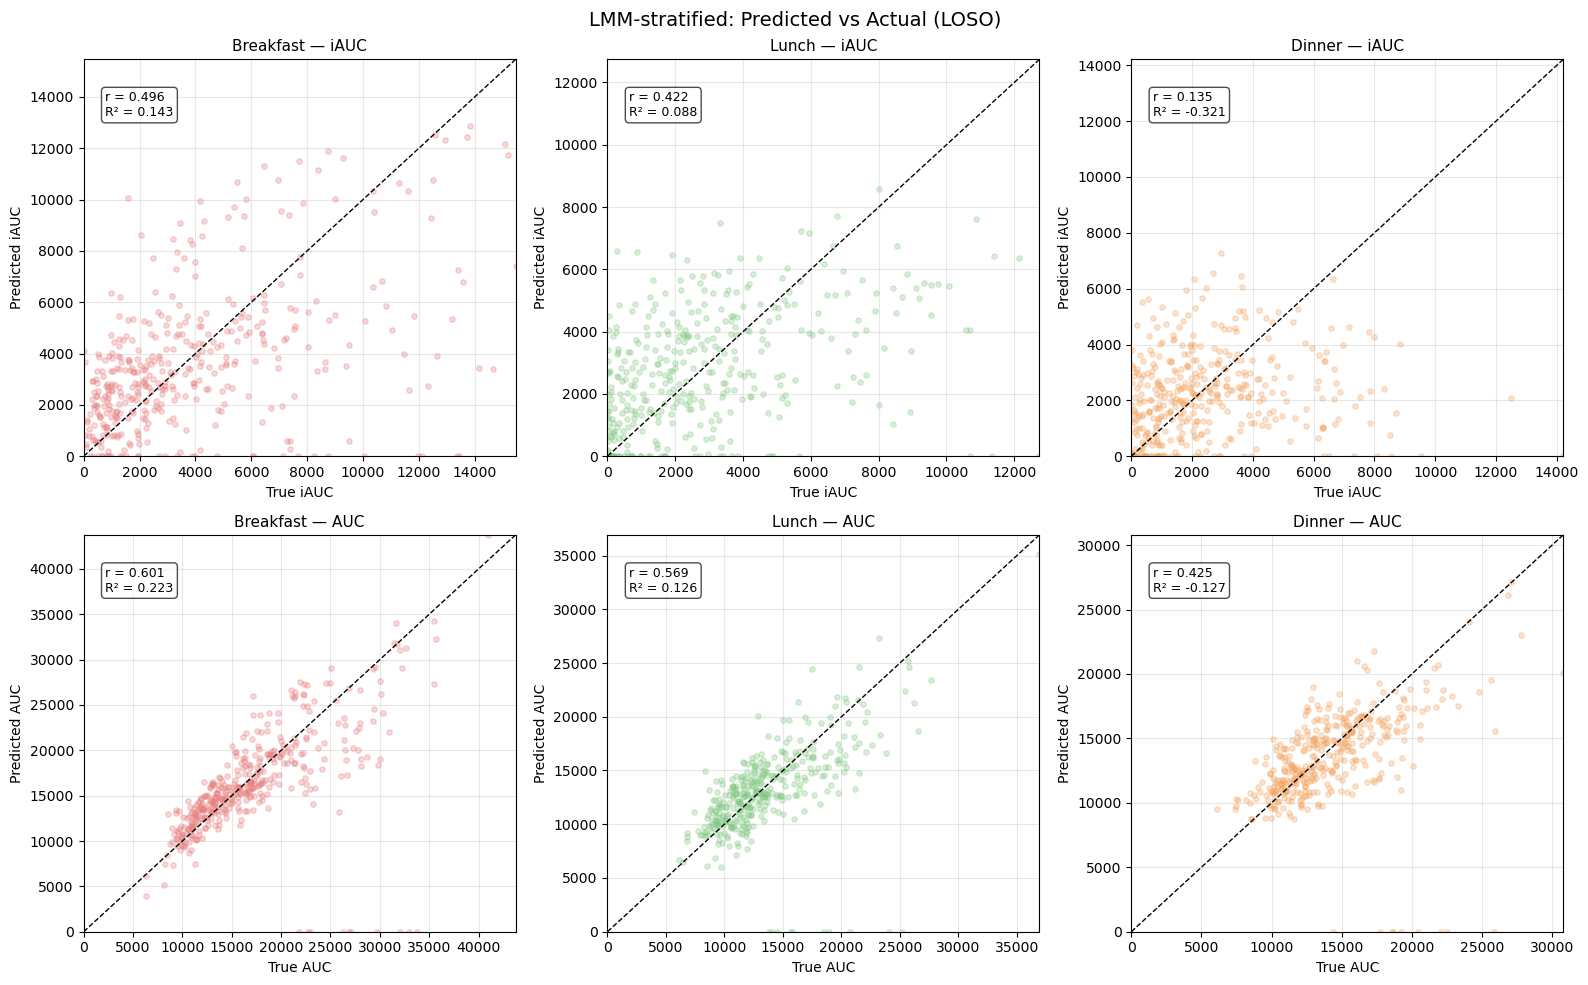

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

strat_data = {
    'Breakfast': lmm_strat_results['Breakfast'],
    'Lunch':     lmm_strat_results['Lunch'],
    'Dinner':    lmm_strat_results['Dinner'],
}
meal_colors = {'Breakfast': '#E87D7D', 'Lunch': '#82C882', 'Dinner': '#F4A460'}

for col, (meal_type, results) in enumerate(strat_data.items()):
    for row, (target_key, target_label) in enumerate([('iAUC', 'iAUC'), ('AUC', 'AUC')]):
        ax  = axes[row, col]
        res = results[target_key][0]  # results_df

        ax.scatter(res['y_true'], res['y_pred'],
                   color=meal_colors[meal_type], alpha=0.3, s=15)

        # perfect prediction line
        max_val = max(res['y_true'].max(), res['y_pred'].max())
        ax.plot([0, max_val], [0, max_val],
                color='black', linestyle='--', linewidth=1.0, label='Perfect fit')

        # annotate with r value
        r = results[target_key][1]['r']
        r2 = results[target_key][1]['R2']
        ax.text(0.05, 0.92, f'r = {r:.3f}\nR² = {r2:.3f}',
                transform=ax.transAxes, fontsize=9,
                verticalalignment='top',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

        ax.set_title(f'{meal_type} — {target_label}', fontsize=11)
        ax.set_xlabel(f'True {target_label}', fontsize=10)
        ax.set_ylabel(f'Predicted {target_label}', fontsize=10)
        ax.set_xlim(0, max_val)
        ax.set_ylim(0, max_val)
        ax.yaxis.grid(True, alpha=0.3)
        ax.xaxis.grid(True, alpha=0.3)
        ax.set_axisbelow(True)

plt.suptitle('LMM-stratified: Predicted vs Actual (LOSO)', fontsize=14)
plt.tight_layout()
plt.savefig('lmm_scatter.png', dpi=150, bbox_inches='tight')
plt.show()